# Module 8 — Fault Tree Analysis

Part of the Root-Cause Analysis Playbook. Program and progress: [CURRICULUM.md](CURRICULUM.md).

## Why you're here: what this module is for

- Cause mapping (Module 7) showed that an effect needs several causes together. Fault tree analysis (FTA) writes that logic down exactly, with AND and OR, and turns it into arithmetic: how often should the failure happen?
- It shows which single failures can cause the problem alone. Those are the places where a backup pays off.
- In DMAIC (Define, Measure, Analyze, Improve, Control), it is an **Analyze** tool. Its numbers also feed Improve: which fix removes the most failures.

**What this module produces:**
1. A fault tree for a daily report email, and the tree's prediction of how many days a year it fails.
2. A check of that prediction against a year of the run log, which shows the prediction is far too low.
3. The broken assumption found and fixed, and a corrected tree whose prediction matches the log.

## From the curriculum

> ## <u>Module 8 — Fault Tree Analysis</u>
>
> **DMAIC phase:** Analyze (formal logic and probability of failure).
>
> **Concepts**
> - The top event, and the AND and OR gates beneath it, down to basic events
> - Minimal cut sets: the smallest combinations of basic events that cause the
>   top event
> - Top-event probability from basic-event probabilities (assuming
>   independence), and what breaks that assumption (common causes)
> - Fault trees for diagnosis (after an incident) vs. for design (before one)
>
> **Why it matters**
> Fault tree analysis turns "it failed because A or B, but only if C" into
> arithmetic. It shows which single failures can cause the problem alone, which
> is where redundancy (a backup) pays off.
>
> **Worked example**
> Fresh, simulated: a daily KPI (Key Performance Indicator) email that is not
> sent or is stale, over a 365-day run log. The analytic top-event probability
> is checked against the simulated frequency. The prediction comes out far too
> low, and the gap leads to a hidden common cause: both of the report's data
> loads read the same source file.
>
> **Resources**
> - [Fault Tree Handbook with Aerospace Applications](https://extapps.ksc.nasa.gov/reliability/Documents/Fault_Tree_Handbook_with_Aerospace_Applications_August_2002.pdf)
>   (NASA, 2002, verified): the standard reference. Read sections 3.8 (cut
>   sets), 5.2 (common cause failures), 7.3 (top event probability), and 9.2–9.3
>   (fault trees for a system in design vs. one already running).
> - [Intro to Fault Tree Analysis](https://accendoreliability.com/intro-to-fault-tree-analysis/)
>   (Accendo Reliability, ~5 min, verified): a short overview of the approach.
>
> **Exercise type:** rank three fixes by the failure days each would have
> saved, and compare with what the tree as designed would have said. Fully
> worked.
>
> **Interview angle:** "How would you make a daily report more reliable?"

## Lesson

### The parts of a fault tree

- **Top event:** the one failure the tree explains, stated exactly (*"the KPI (Key Performance Indicator) email is not sent, or is sent with stale data, on a given day"*).
- **Gates:** the logic under each event.
  - **OR gate:** the event above happens if **any one** of the events below happens.
  - **AND gate:** the event above happens only if **all** of the events below happen together.
- **Basic events:** the bottom of the tree, failures that are not broken down further (*"the mail server fails"*). Each has a probability: here, the share of days it happens.

### Minimal cut sets

A **cut set** is a set of basic events that, if they all happen, cause the top event. A **minimal cut set** is one with nothing extra: remove any event from it and the top event no longer follows.
- A minimal cut set with **one** event is a **single point of failure**: that event alone causes the top event.
- A minimal cut set with **two or more** events needs them to happen together. That is what a backup buys.

### From the tree to a probability

If the basic events are **independent** (one failing does not make another more likely):
- **AND gate:** multiply the probabilities. Two events at 10% each happen together on 10% × 10% = 1% of days.
- **OR gate:** the event above does *not* happen only if *none* below happens, so P(above) = 1 − (1 − p₁) × (1 − p₂) × …
- **Rare-event shortcut:** when every probability is small, an OR gate is close to the plain sum, p₁ + p₂ + … The sum is always slightly above the exact value, never below.

### When independence breaks: common causes

The multiplication at an AND gate is only right if the events are independent. A **common cause** (one thing that makes several basic events fail together) breaks it. Two backups that depend on the same thing fail together far more often than the product says, so the tree's prediction comes out too low. The fix in the tree: give the common cause its own basic event. It then shows up as what it is, a single point of failure.

### Two uses

- **Design (before an incident):** build the tree from how the system is meant to work, and find the single points of failure before they cause trouble.
- **After incidents:** two checks.
  - **Diagnosis:** trace which minimal cut set produced each incident.
  - **Validating the tree:** compare how often the tree says the top event should happen with how often it did. A large gap means the tree is wrong about how the system fails, and finding where it is wrong is root-cause work.

## Worked example: the daily KPI email

**Data choice: fresh, simulated.** The lesson needs a system whose true failure logic is known, so the tree's prediction can be checked against it. Every rate in the simulation is a chosen example (`common.simulate_report_runs`, fixed seed: the seed is the starting number of the random generator, so every run gives the same log). The planted truth is revealed at the end.

**The system:** every morning a scheduler starts a report job that emails the KPI report to the leadership team. The report reads data loaded overnight. To be safe, the team built two nightly loads, a **primary** and a **backup**. Both loads read the same nightly source file. The report uses whichever load succeeded. If both fail, the report is built on yesterday's data and sent anyway: **stale**.

**The data:** a run log, one row per day of 2025. For each day it records whether the source file arrived on time, whether each load succeeded, whether the scheduler started the job, whether the mail server sent it, and the email's outcome.

**The question:** the email fails too often. Where does the failure come from, and which fix would remove the most failures?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import fisher_exact, poisson
import common
from common import show, BLUE, ORANGE, AQUA, GREY

log = common.simulate_report_runs()
n = len(log)
print("What is in the run log? (simulated)")
print(f"  days = {n}")
print(f"  dates = {log['date'].min():%Y-%m-%d} to {log['date'].max():%Y-%m-%d}")
print(f"  missing values = {int(log.isna().sum().sum())}")
print()
print("How did the email turn out?")
for k, v in log["email"].value_counts().items():
    print(f"  {k} = {v} days")
top_days = int((log["email"] != "sent, fresh").sum())
print(f"  failed (not sent, or sent stale) = {top_days} days")

What is in the run log? (simulated)
  days = 365
  dates = 2025-01-01 to 2025-12-31
  missing values = 0

How did the email turn out?
  sent, fresh = 345 days
  sent, stale = 14 days
  not sent = 6 days
  failed (not sent, or sent stale) = 20 days


**Observation:** the email failed on 20 of the 365 days (5.5%): 6 days not sent, 14 days sent with stale data.

**Top event:** the KPI email is not sent, or is sent with stale data, on a given day.

### Step 1 — What does the tree look like, as the system was designed?

The email fails if the scheduler fails, **or** the mail server fails, **or** the data is stale. The data is stale only if the primary load fails **and** the backup load fails.

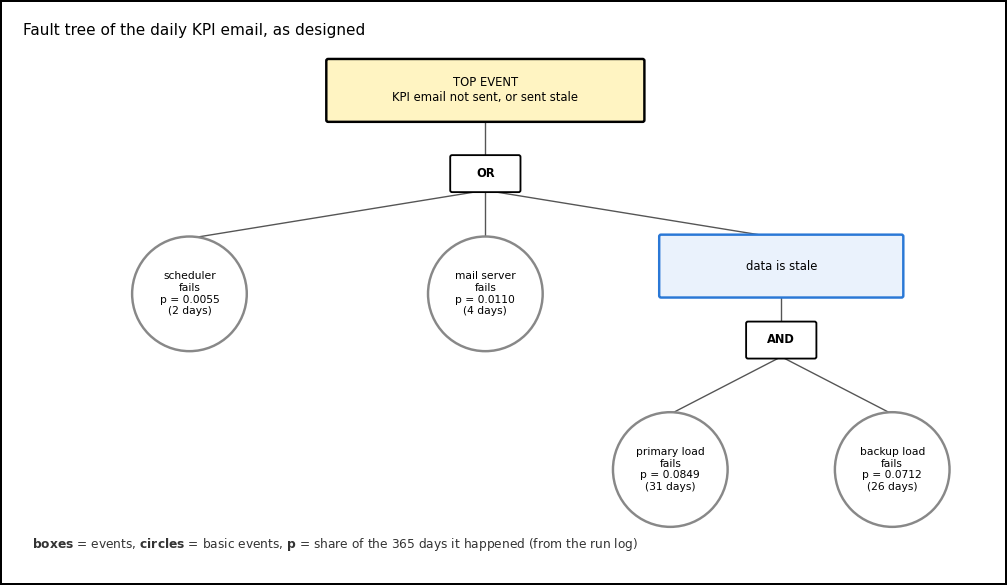

In [2]:
from matplotlib.patches import FancyBboxPatch, Circle

def event(ax, x, y, text, color=BLUE, w=2.6, fc="#eaf2fc"):
    ax.add_patch(FancyBboxPatch((x - w / 2, y - 0.32), w, 0.64, boxstyle="round,pad=0.02", fc=fc, ec=color, lw=1.6))
    ax.text(x, y, text, ha="center", va="center", fontsize=7.6)

def gate(ax, x, y, kind):
    ax.add_patch(FancyBboxPatch((x - 0.36, y - 0.18), 0.72, 0.36, boxstyle="round,pad=0.02", fc="white", ec="black", lw=1.2))
    ax.text(x, y, kind, ha="center", va="center", fontsize=7.5, fontweight="bold")

def basic(ax, x, y, text, color=GREY):
    ax.add_patch(Circle((x, y), 0.62, fc="white", ec=color, lw=1.6))
    ax.text(x, y, text, ha="center", va="center", fontsize=7)

def line(ax, x1, y1, x2, y2):
    ax.plot([x1, x2], [y1, y2], color="#555555", lw=0.9, zorder=0)

def rate(col):
    return (~log[col]).mean(), int((~log[col]).sum())

def label(name, col):
    p, k = rate(col)
    return f"{name}\np = {p:.4f}\n({k} days)"

fig, ax = plt.subplots(figsize=(10, 5.2))
event(ax, 0, 3.2, "TOP EVENT\nKPI email not sent, or sent stale", color="black", w=3.4, fc="#fff4c2")
line(ax, 0, 2.88, 0, 2.48); gate(ax, 0, 2.3, "OR")
for x in (-3.2, 0, 3.2):
    line(ax, 0, 2.12, x, 1.6)
basic(ax, -3.2, 1.0, label("scheduler\nfails", "scheduler_ok"))
basic(ax, 0, 1.0, label("mail server\nfails", "mail_ok"))
event(ax, 3.2, 1.3, "data is stale")
line(ax, 3.2, 0.98, 3.2, 0.68); gate(ax, 3.2, 0.5, "AND")
for x in (2.0, 4.4):
    line(ax, 3.2, 0.32, x, -0.3)
basic(ax, 2.0, -0.9, label("primary load\nfails", "primary_load_ok"))
basic(ax, 4.4, -0.9, label("backup load\nfails", "backup_load_ok"))
ax.text(-4.9, -1.75, r"$\bf{boxes}$ = events, $\bf{circles}$ = basic events, $\bf{p}$ = share of the 365 days it happened (from the run log)", fontsize=8, color="#333333")
ax.set_xlim(-5, 5.4); ax.set_ylim(-1.9, 3.7); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Fault tree of the daily KPI email, as designed", fontsize=10, loc="left")
plt.tight_layout(); plt.show()

**The minimal cut sets** (read from the tree):
1. {scheduler fails}: a single point of failure
2. {mail server fails}: a single point of failure
3. {primary load fails, backup load fails}: needs both together

The backup was built so that a load failure alone never makes the email stale. On paper it worked: the only data cut set has two events in it.

**Note:** this is the tree's structure as designed, with each basic event's rate measured from the run log.

### Step 2 — How often does each basic event happen?

In [3]:
cols = {"scheduler fails": "scheduler_ok", "mail server fails": "mail_ok",
        "primary load fails": "primary_load_ok", "backup load fails": "backup_load_ok"}
p = {k: rate(c)[0] for k, c in cols.items()}
show(pd.DataFrame({"basic event": list(cols), "days": [rate(c)[1] for c in cols.values()],
                   "of days": [n] * len(cols), "share of days (p)": [f"{v:.4f}" for v in p.values()]}))

basic event         days  of days  share of days (p)
scheduler fails        2      365             0.0055
mail server fails      4      365             0.0110
primary load fails    31      365             0.0849
backup load fails     26      365             0.0712


**Observation:** each load fails on fewer than one day in ten (primary 31 days, backup 26 days). The scheduler and the mail server fail rarely (2 and 4 days).

### Step 3 — What does the tree predict?

In [4]:
p_stale = p["primary load fails"] * p["backup load fails"]
p_top = 1 - (1 - p["scheduler fails"]) * (1 - p["mail server fails"]) * (1 - p_stale)
print("The tree's arithmetic, assuming the basic events are independent:")
print("(computed from unrounded rates, so the last digit can differ from multiplying the rounded ones)")
p_not_sent = 1 - (1 - p["scheduler fails"]) * (1 - p["mail server fails"])
print(f"  AND gate, data is stale = {p['primary load fails']:.4f} × {p['backup load fails']:.4f} = {p_stale:.5f}")
print(f"  OR gate, top event = 1 − (1 − {p['scheduler fails']:.4f}) × (1 − {p['mail server fails']:.4f}) × (1 − {p_stale:.5f}) = {p_top:.5f}")
print(f"  rare-event shortcut = {p['scheduler fails']:.4f} + {p['mail server fails']:.4f} + {p_stale:.5f} = {p['scheduler fails'] + p['mail server fails'] + p_stale:.5f}")
print()
print("Predicted against the run log, failure days in 2025:")
print(f"  all failures predicted = {p_top:.5f} × {n} = {p_top * n:.1f}")
print(f"  all failures in the log = {top_days}")
print(f"  not sent, predicted = {p_not_sent:.5f} × {n} = {p_not_sent * n:.1f}")
print(f"  not sent, in the log = {int((log['email'] == 'not sent').sum())}")
print(f"  stale, predicted = {p_stale:.5f} × {n} = {p_stale * n:.1f}")
print(f"  stale, in the log = {int((log['email'] == 'sent, stale').sum())}")
print()
print("If the tree were right, how often would a year have this many failure days or more?")
print(f"  failure days in a year follow a Poisson distribution with mean {p_top * n:.1f}")
print(f"  chance of {top_days} or more = sum, for every k from {top_days} up, of e^(−{p_top * n:.1f}) × {p_top * n:.1f}^k ÷ k! = {poisson.sf(top_days - 1, p_top * n):.4f}")

The tree's arithmetic, assuming the basic events are independent:
(computed from unrounded rates, so the last digit can differ from multiplying the rounded ones)
  AND gate, data is stale = 0.0849 × 0.0712 = 0.00605
  OR gate, top event = 1 − (1 − 0.0055) × (1 − 0.0110) × (1 − 0.00605) = 0.02233
  rare-event shortcut = 0.0055 + 0.0110 + 0.00605 = 0.02249

Predicted against the run log, failure days in 2025:
  all failures predicted = 0.02233 × 365 = 8.2
  all failures in the log = 20
  not sent, predicted = 0.01638 × 365 = 6.0
  not sent, in the log = 6
  stale, predicted = 0.00605 × 365 = 2.2
  stale, in the log = 14

If the tree were right, how often would a year have this many failure days or more?
  failure days in a year follow a Poisson distribution with mean 8.2
  chance of 20 or more = sum, for every k from 20 up, of e^(−8.2) × 8.2^k ÷ k! = 0.0003


**Observation:** the tree predicts 8.2 failure days a year. The log has 20.
- Not sent: the tree predicts 6.0, the log has 6.
- Stale: the tree predicts 2.2, the log has 14. The whole gap is here.

**How to read the last line:** if the tree were right, the number of failure days in a year would vary by chance around 8.2. A year with 20 or more would happen with a chance of 0.0003. (This uses the Poisson distribution, the usual model for a count of rare events.)

**Conclusion:** the gap is not chance. The tree is wrong about how the email fails, and the wrong part is the stale branch, under the AND gate.

### Step 4 — Which assumption broke?

The AND gate multiplied the two load failures, which is only right if they are independent. If they are, the backup should fail just as often on days the primary failed as on days it did not:

In [5]:
pf = ~log["primary_load_ok"]
bf = ~log["backup_load_ok"]
table = [[int((pf & bf).sum()), int((pf & ~bf).sum())], [int((~pf & bf).sum()), int((~pf & ~bf).sum())]]
show(pd.DataFrame({"primary load": ["failed", "succeeded"], "backup failed": [table[0][0], table[1][0]],
                   "backup succeeded": [table[0][1], table[1][1]], "days": [int(pf.sum()), int((~pf).sum())],
                   "backup failure rate": [f"{bf[pf].mean():.1%}", f"{bf[~pf].mean():.1%}"]}))
print()
N_, K_, n_, k_ = n, int(bf.sum()), int(pf.sum()), table[0][0]
mant, expo = f"{fisher_exact(table)[1]:.1e}".split("e")
print(f"If the two loads failed independently, how likely is it that both would fail on {k_} or more of the same days?")
print("  P(k) = chance that both fail on exactly k days, if independent = C(K, k) × C(N − K, n − k) ÷ C(N, n)")
print("  C(a, b) = number of ways to choose b days out of a = a! ÷ (b! × (a − b)!)")
print()
print("  parameters:")
print(f"      K = days the backup failed = {K_}")
print(f"      k = days both failed, runs from {k_} (days both failed in the log) to {min(K_, n_)} (the smaller of K and n)")
print(f"      N = all days = {N_}")
print(f"      n = days the primary failed = {n_}")
print()
print(f"  p-value = the chance of {k_} or more shared failure days, if the loads were independent")
print(f"  p-value = sum of P(k) over that range = {mant} × 10^({str(int(expo)).replace('-', '−')})")
print()
print("  note: K and n are interchangeable.")

primary load  backup failed  backup succeeded  days  backup failure rate
failed                   14                17    31                45.2%
succeeded                12               322   334                 3.6%

If the two loads failed independently, how likely is it that both would fail on 14 or more of the same days?
  P(k) = chance that both fail on exactly k days, if independent = C(K, k) × C(N − K, n − k) ÷ C(N, n)
  C(a, b) = number of ways to choose b days out of a = a! ÷ (b! × (a − b)!)

  parameters:
      K = days the backup failed = 26
      k = days both failed, runs from 14 (days both failed in the log) to 26 (the smaller of K and n)
      N = all days = 365
      n = days the primary failed = 31

  p-value = the chance of 14 or more shared failure days, if the loads were independent
  p-value = sum of P(k) over that range = 2.2 × 10^(−10)

  note: K and n are interchangeable.


**Observation:** on the 31 days the primary load failed, the backup failed on 14 (45.2%). On the 334 days the primary succeeded, the backup failed on 12 (3.6%). The p-value is 2.2 × 10^(−10), so this is not chance.

**Conclusion:** the two loads are not independent. They fail together far more often than the AND gate assumed.

**Hypothesis:** both loads depend on something they share. By design, both read the same source file, and the run log records whether it arrived on time:

In [6]:
late = ~log["source_file_on_time"]
rows = []
for name, mask in [("late", late), ("on time", ~late)]:
    rows.append({"source file": name, "days": int(mask.sum()),
                 "primary failed days": int(pf[mask].sum()), "primary failed %": f"{pf[mask].mean():.1%}",
                 "backup failed days": int(bf[mask].sum()), "backup failed %": f"{bf[mask].mean():.1%}",
                 "both failed days": int((pf & bf)[mask].sum()), "both failed %": f"{(pf & bf)[mask].mean():.1%}"})
show(pd.DataFrame(rows))
print()
both_on_time = int((pf & bf & ~late).sum())
print(f"Stale days in the log = {int((pf & bf).sum())}")
print(f"  on days the file was late = {int((pf & bf & late).sum())}")
print(f"  on days the file was on time = {both_on_time}")

source file  days  primary failed days  primary failed %  backup failed days  backup failed %  both failed days  both failed %
late           13                   13            100.0%                  13           100.0%                13         100.0%
on time       352                   18              5.1%                  13             3.7%                 1           0.3%

Stale days in the log = 14
  on days the file was late = 13
  on days the file was on time = 1


**Observation:** on the 13 days the source file was late, both loads failed every time.

**Observation:** on the 352 days it was on time:
- the primary failed on 5.1% of days
- the backup failed on 3.7% of days
- both failed together on only 1 day

**Observation:** of the 14 stale days, 13 had a late file.

**Conclusion:** the late source file is a **common cause**. Both loads read the same file, so when it is late, the backup fails along with the primary. The backup protects against a load failing on its own, but not against the file being late.

### Step 5 — The corrected tree

The late file gets its own basic event. "Data is stale" becomes an OR: the file is late, **or** both loads fail (source file on time).

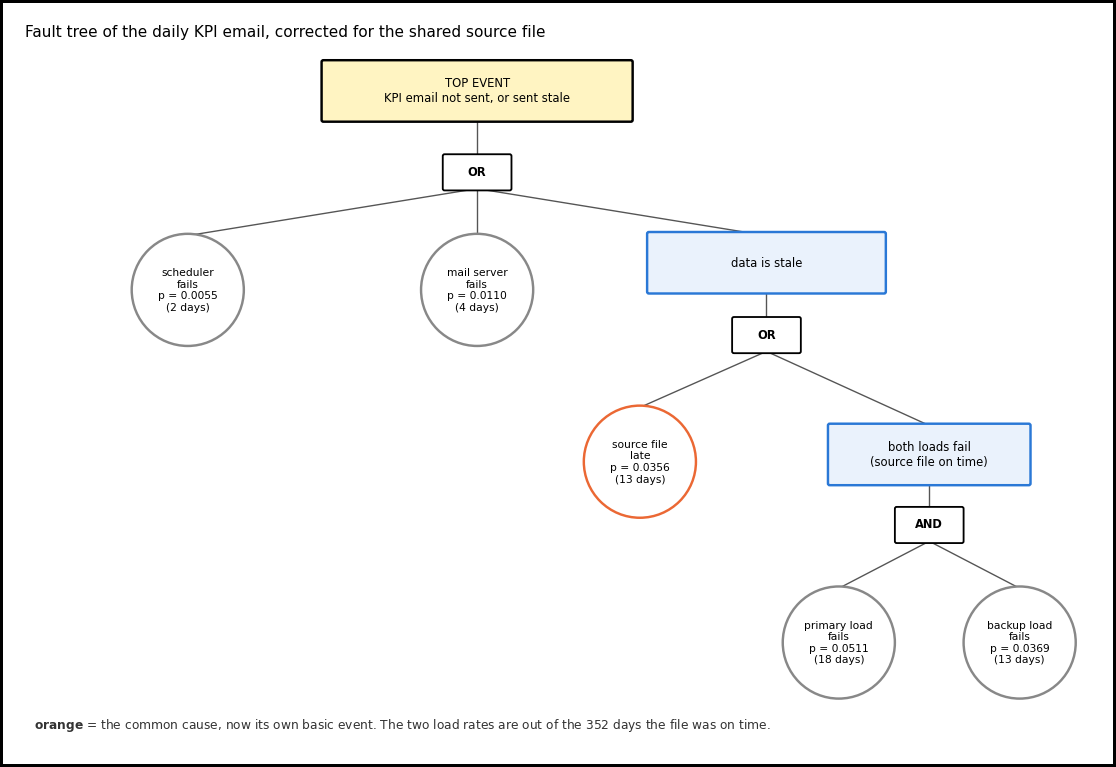

The corrected tree's arithmetic:
  AND gate, both loads fail (source file on time) = 0.0511 × 0.0369 = 0.00189
  OR gate, data is stale = 1 − (1 − 0.0356) × (1 − 0.00189) = 0.03744
  OR gate, top event = 1 − (1 − 0.0055) × (1 − 0.0110) × (1 − 0.03744) = 0.05320

Failure days in 2025:
  tree as designed = 8.2
  corrected tree = 19.4
  in the log = 20


In [7]:
on = log[log["source_file_on_time"]]
p_late = late.mean()
p_prim_own = (~on["primary_load_ok"]).mean()
p_back_own = (~on["backup_load_ok"]).mean()

fig, ax = plt.subplots(figsize=(10, 7))
event(ax, 0, 3.2, "TOP EVENT\nKPI email not sent, or sent stale", color="black", w=3.4, fc="#fff4c2")
line(ax, 0, 2.88, 0, 2.48); gate(ax, 0, 2.3, "OR")
for x in (-3.2, 0, 3.2):
    line(ax, 0, 2.12, x, 1.6)
basic(ax, -3.2, 1.0, label("scheduler\nfails", "scheduler_ok"))
basic(ax, 0, 1.0, label("mail server\nfails", "mail_ok"))
event(ax, 3.2, 1.3, "data is stale")
line(ax, 3.2, 0.98, 3.2, 0.68); gate(ax, 3.2, 0.5, "OR")
line(ax, 3.2, 0.32, 1.8, -0.3); line(ax, 3.2, 0.32, 5.0, -0.5)
basic(ax, 1.8, -0.9, f"source file\nlate\np = {p_late:.4f}\n({int(late.sum())} days)", color=ORANGE)
event(ax, 5.0, -0.82, "both loads fail\n(source file on time)", w=2.2)
line(ax, 5.0, -1.14, 5.0, -1.42); gate(ax, 5.0, -1.6, "AND")
line(ax, 5.0, -1.78, 4.0, -2.3); line(ax, 5.0, -1.78, 6.0, -2.3)
basic(ax, 4.0, -2.9, f"primary load\nfails\np = {p_prim_own:.4f}\n({int((~on['primary_load_ok']).sum())} days)")
basic(ax, 6.0, -2.9, f"backup load\nfails\np = {p_back_own:.4f}\n({int((~on['backup_load_ok']).sum())} days)")
ax.text(-4.9, -3.85, r"$\bf{orange}$ = the common cause, now its own basic event. The two load rates are out of the 352 days the file was on time.", fontsize=8, color="#333333")
ax.set_xlim(-5, 6.8); ax.set_ylim(-4.0, 3.7); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Fault tree of the daily KPI email, corrected for the shared source file", fontsize=10, loc="left")
plt.tight_layout(); plt.show()

p_stale2 = p_late + (1 - p_late) * p_prim_own * p_back_own
p_top2 = 1 - (1 - p["scheduler fails"]) * (1 - p["mail server fails"]) * (1 - p_stale2)
print("The corrected tree's arithmetic:")
print(f"  AND gate, both loads fail (source file on time) = {p_prim_own:.4f} × {p_back_own:.4f} = {p_prim_own * p_back_own:.5f}")
print(f"  OR gate, data is stale = 1 − (1 − {p_late:.4f}) × (1 − {p_prim_own * p_back_own:.5f}) = {p_stale2:.5f}")
print(f"  OR gate, top event = 1 − (1 − {p['scheduler fails']:.4f}) × (1 − {p['mail server fails']:.4f}) × (1 − {p_stale2:.5f}) = {p_top2:.5f}")
print()
print("Failure days in 2025:")
print(f"  tree as designed = {p_top * n:.1f}")
print(f"  corrected tree = {p_top2 * n:.1f}")
print(f"  in the log = {top_days}")

**Observation:** the corrected tree predicts 19.4 failure days. The log has 20.

**Caveat:** using the log to correct the tree is right. The caveat is about the check: the corrected tree's rates come from this same log, so matching it is partly built in. The real test is next year's log, which the tree has not seen.

**The minimal cut sets now:**
1. {scheduler fails}
2. {mail server fails}
3. {source file late}: a **new single point of failure**, and the biggest one, at 13 days
4. {primary load fails, backup load fails} (source file on time)

**Conclusion:** the backup load was meant to remove the data as a single point of failure. It did not, because both loads read the same file. The tree as designed hid that, and only the comparison with the log exposed it.

### Does this hold beyond one simulated year?

The same comparison on ten simulated years (different random seeds):

In [8]:
def predict(df):
    f = lambda c: (~df[c]).mean()
    s, m = f("scheduler_ok"), f("mail_ok")
    designed = 1 - (1 - s) * (1 - m) * (1 - f("primary_load_ok") * f("backup_load_ok"))
    lt = (~df["source_file_on_time"]).mean()
    o = df[df["source_file_on_time"]]
    stale = lt + (1 - lt) * (~o["primary_load_ok"]).mean() * (~o["backup_load_ok"]).mean()
    corrected = 1 - (1 - s) * (1 - m) * (1 - stale)
    return designed * len(df), corrected * len(df), int((df["email"] != "sent, fresh").sum())

res = pd.DataFrame([(seed, *predict(common.simulate_report_runs(seed))) for seed in [2026] + list(range(1, 10))],
                   columns=["seed", "designed", "corrected", "in the log"])
show(pd.DataFrame({"seed": ["2026 (the main example)"] + [str(x) for x in res["seed"].iloc[1:]], "tree as designed": res["designed"].map("{:.1f}".format),
                   "corrected tree": res["corrected"].map("{:.1f}".format), "failure days in the log": res["in the log"],
                   "corrected − log": (res["corrected"] - res["in the log"]).map(lambda v: f"{v:+.1f}".replace("-", "−"))}))
print()
print(f"Years where the log has more failure days than the tree as designed = {(res['in the log'] > res['designed']).sum()} of {len(res)}")
print("  this is planted on purpose: the simulation makes both loads fail whenever the file is late, and the tree as designed ignores that, so it predicts too few failure days every year")
print(f"Largest gap between the corrected tree and the log = {(res['corrected'] - res['in the log']).abs().max():.1f} days")
print()
planted = 1 - (1 - 0.015) * (1 - 0.01) * (1 - (1 - (1 - 0.04) * (1 - 0.06 * 0.05)))
print("With the rates planted in the simulation:")
print("  file late = 4%, primary fails = 6%, backup fails = 5%, scheduler fails = 1.5%, mail server fails = 1%")
print("an average year has:")
print(f"  1 − (1 − 0.015) × (1 − 0.01) × (1 − (1 − (1 − 0.04) × (1 − 0.06 × 0.05))) = {planted:.4f}")
print(f"  {planted:.4f} × {n} = {planted * n:.1f} failure days")

seed                     tree as designed  corrected tree  failure days in the log  corrected − log
2026 (the main example)               8.2            19.4                       20             −0.6
1                                    13.7            28.0                       27             +1.0
2                                    14.6            22.3                       22             +0.3
3                                    13.9            23.8                       22             +1.8
4                                    15.0            23.5                       24             −0.5
5                                    15.2            28.9                       30             −1.1
6                                     5.4             9.8                        9             +0.8
7                                    12.3            27.3                       28             −0.7
8                                     4.6            14.1                       13             +1.1


**Observation:** in all 10 years the tree as designed predicts too few failure days. The corrected tree is never more than 1.8 days off (each year's tree is fitted on that year's own log, so this is a consistency check, not a forecast). 2025's 20 failure days were a slightly good year: the planted rates give 24.3 on average.

**The truth, as planted in the simulation:** the source file is late on 4% of days, and on those days both loads fail. Otherwise the primary fails on 6% of days and the backup on 5%, independently. The scheduler fails on 1.5% of days and the mail server on 1%.

## Exercise — Which fix first?

The team can afford one fix this quarter. Assume each one fully works:
- **A.** a second mail server, so the mail server is no longer a single point of failure
- **B.** a watchdog that restarts the scheduler when it fails
- **C.** the backup load reads its own copy of the source file, delivered by a separate route, so a late delivery no longer stops it

How many of 2025's failure days would each fix have saved? And what would the tree as designed have said about fix C?

In [9]:
stale = pf & bf
mail_only = int(((~log["mail_ok"]) & log["scheduler_ok"] & ~stale).sum())
sched_only = int(((~log["scheduler_ok"]) & log["mail_ok"] & ~stale).sum())
stale_late = int(((log["email"] == "sent, stale") & late).sum())
print("Failure days each fix would have saved in 2025 (days with no other failure that day):")
print(f"  A. second mail server = {mail_only}")
print(f"  B. scheduler watchdog = {sched_only}")
print(f"  C. backup with its own copy of the file = {stale_late}  (stale days with a late file)")
print()
print("What the tree as designed says about fix C:")
print("  it already treats the two loads as independent (before fix C: wrongfully, after: rightfully so), so fix C changes nothing in it = 0 days saved")

Failure days each fix would have saved in 2025 (days with no other failure that day):
  A. second mail server = 4
  B. scheduler watchdog = 2
  C. backup with its own copy of the file = 13  (stale days with a late file)

What the tree as designed says about fix C:
  it already treats the two loads as independent (before fix C: wrongfully, after: rightfully so), so fix C changes nothing in it = 0 days saved


**Answer:**
- Fix **C** saves the most: 13 of the 20 failure days. Fix A saves 4 and fix B saves 2.
- Suppose the team had trusted the tree as designed and never checked it against the log. That tree already treats the two loads as independent, which is exactly what fix C makes true. So in that tree, fix C changes nothing: it saves 0 days and ranks **last**.
- In that same tree, A saves 4 days and B saves 2. So that team would rank A first, B second, C last.
- In the corrected tree after fix C, C saves 13 days, A 4 and B 2: C ranks **first**. A wrong tree does not just get the total wrong: it points the fix at the wrong place.

**Caveats:**
- The days are not equal: C's 13 were stale emails, while A's 4 and B's 2 were emails never sent. Counting days treats them as equally bad.
- **Hypothesis:** C works only if the file is late because of its delivery. If the source data itself is late, a second copy is late too, and C saves nothing. Check why the file was late before building C.
- These counts come from one year (2 scheduler and 4 mail server failures). They are estimates, not a forecast.

## Key takeaways

- **A fault tree writes the failure logic exactly:** OR = any one event below is enough, AND = all of them are needed together.
- **Minimal cut sets show the single points of failure.** A minimal cut set with one event is where a backup pays off.
- **The tree's arithmetic assumes independence.** A common cause (here, the shared source file) makes events fail together, and the tree predicts too few failures: 8.2 days against 20 in the log.
- **Validate the tree: compare its prediction with what happened.** A large gap means the tree is wrong about how the system fails. Here it led straight to the hidden single point of failure.
- **Give a common cause its own basic event.** The corrected tree predicts 19.4 days, and the late file shows up as the biggest single point of failure.
- **A wrong tree ranks fixes wrongly.** The tree as designed rated the best fix (13 of 20 days saved) at zero.
- **In DMAIC, this is Analyze, and it prepares Improve:** the cut sets and their rates rank where each fix should go.